In [227]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import diags
from scipy.sparse.linalg import eigs
from scipy import linalg
from sklearn.metrics.pairwise import cosine_similarity
import networkx as nx
from sklearn.metrics import adjusted_rand_score

In [211]:
def calculate_ipr(vector):
    """
    Calculate the Inverse Participation Ratio (IPR) for a given vector.
    IPR is the sum of the fourth power of the elements in the vector.
    """
    return np.sum(vector**4)

def update_regularization_matrix(Z, A, feature_matrix, threshold=0.1):
    """
    Update the diagonal elements of matrix Z based on the IPR of the feature vectors.
    A penalty is applied if the IPR exceeds a certain threshold (indicating high localization).
    
    Parameters:
    - Z: Initial regularization matrix (diagonal, 4x4 in this case for 4 nodes).
    - feature_matrix: The matrix where each row is a feature vector (10x4).
    - threshold: A value to decide when to apply a penalty based on IPR.
    """
    for i, vector in enumerate(feature_matrix):  # Iterate over the columns (nodes' feature vectors)
        ipr_value = calculate_ipr(vector)
        if ipr_value > threshold:
            # print(f"Node {i} has high IPR ({ipr_value}), applying penalty.")
            # Apply a penalty by modifying the diagonal element of Z
            Z[i, i] += 1  # Example penalty: increase the diagonal element by 1
    return Z

In [230]:
# Non-backtracking matrix-based method to estimate number of communities
def estimate_num_communities(A, features, initial_k=4, step=1, max_k=10):
    # Step 1: Calculate the degrees of the nodes
    degrees = np.sum(A, axis=1)
    diag_degrees = diags(degrees)
    
    # Step 2: Construct the non-backtracking matrix
    non_backtracking_matrix = np.block([
        [A, diag_degrees - np.eye(len(A))],
        [-np.eye(len(A)), np.zeros_like(A)]
    ])
    
    # Step 3: Compute the norm of the non-backtracking matrix
    radius = np.sqrt(np.linalg.norm(non_backtracking_matrix,'fro'))  # Frobenius norm
    print("Radius of the non-backtracking matrix:", radius)
    # radius = np.sqrt(np.sum(np.abs(non_backtracking_matrix.data)**2))

    k = initial_k
    communities_count = 0
    all_real_found = False

    eigvals = linalg.eigvals(non_backtracking_matrix)
    # eigvals = np.sort(eigvals)[::-1]
    # plot the eigenvalues
    plt.plot(eigvals.real, eigvals.imag, 'o')
    plt.xlabel('Re')
    plt.ylabel('Im')
    plt.title('Eigenvalues of the non-backtracking matrix')
    plt.show()
    
    # print the eigenvalues in a file
    np.savetxt('eigenvalues.txt', eigvals)
    while not all_real_found and k <= max_k:
    # while k <= max_k:
        # Step 4: Compute the eigenvalues of the non-backtracking matrix
        # sort the eigenvalues in descending order
        # get the top k eigenvalues
        k_eigvals = eigvals[:k]
        print(k_eigvals)
        # print(radius)
        
        # Step 5: Filter out eigenvalues inside the circle with radius equal to the norm of the matrix
        eigen_distances = np.abs(k_eigvals)  # Magnitude of each eigenvalue
        outside_circle = eigen_distances > radius
        
        # Count the number of eigenvalues outside the circle
        communities_count = np.sum(outside_circle)
        print(f"Number of eigenvalues outside the circle: {communities_count}")
        if communities_count > 0:
           all_real_found = True  # Stop if we have enough eigenvalues to count
        
        else:
            # Increase k and try again
            k += step

    return communities_count

# Function to initialize P randomly
def initialize_P(n, k):
    P = np.random.rand(n, k)
    P /= np.sum(P, axis=1)[:, np.newaxis]  # Normalize each row to sum to 1
    return P

# Symmetric NMF update rule
def update_P(Lz, P, beta=0.5):
    numerator = np.dot(Lz, P)
    denominator = np.dot(np.dot(P, P.T), P)
    denominator[denominator == 0] = 1e-10  # Avoid division by zero
    P = P * ((1 - beta) + beta * numerator / denominator)
    P_updated = np.maximum(np.dot(np.dot(Lz, P), np.linalg.inv(np.dot(P.T, P))), 0) # Non-negative constraint
    return P_updated

# CDNMF algorithm
def CDNMF(A, features, k, num_iterations=100, beta=0.5):
    n = A.shape[0]
    
    # Step 1: Estimate the number of communities (k) using spectral analysis
    # k = estimate_num_communities(A, features)
    # k = 8  # For simplicity, we will use a fixed number of communities
    # print(f"Estimated number of communities: {k}")
    
    # Step 2: Initialize P matrix randomly
    P = initialize_P(n, k)
    
    # Step 3: Initialize regularization matrix Z
    Z = np.zeros((n, n))
    Z = update_regularization_matrix(Z, A, features, threshold=0.01)
    
    # Step 4: Compute regularized Laplacian Lz
    Lz = A + Z
    
    # Step 5: Iteratively update P using the update rule
    obj_value = np.inf
    benchmark_value = np.linalg.norm(A, 'fro') * 0.0001
    # print(f"Benchmark value: {benchmark_value}")
    for iteration in range(num_iterations):
        P = update_P(Lz, P, beta)

        # Compute the objective function value
        obj_value = np.linalg.norm(A - np.dot(P, P.T), 'fro')
        # if iteration % 10 == 0:
            # print(f"Objective function value after {iteration+1} iterations: {obj_value}")

        # If the objective value is below a certain threshold, stop the iterations
        if obj_value < benchmark_value:
            break

    # Normalize P so that each row sums to 1
    P /= np.sum(P, axis=1)[:, np.newaxis]
    
    # Assign nodes to communities based on maximum membership value
    communities = np.argmax(P, axis=1)
    
    return communities, P


In [220]:
# Function to parse .cites and .content files and build the adjacency matrix
def parse_dataset(cites_file, content_file):
    # Parse the .content file
    features = []
    node_id_to_index = {}
    class_labels = set()
    actual_labels = []
    num_nodes = 0
    with open(content_file, "r") as file:
        for line in file:
            parts = line.strip().split("\t")
            node_id = parts[0]
            node_id_to_index[node_id] = num_nodes

            feature_vector = np.array([float(x) for x in parts[1:-1]])
            feature_vector = feature_vector / np.linalg.norm(feature_vector)
            features.append(feature_vector)

            class_label = parts[-1]
            class_labels.add(class_label)
            actual_labels.append(class_label)
            
            num_nodes += 1

    # make number of features consistent
    max_features = max([len(feature) for feature in features])
    for i in range(len(features)):
        features[i] = np.pad(features[i], (0, max_features - len(features[i])), 'constant')
    
    features = np.array(features)

    # Parse the .cites file
    edges = []
    with open(cites_file, "r") as file:
        for line in file:
            parts = line.strip().split("\t")
            edges.append((parts[0], parts[1]))
    
    # Build the adjacency matrix
    A = np.zeros((num_nodes, num_nodes))
    for edge in edges:
        if edge[0] not in node_id_to_index or edge[1] not in node_id_to_index:
            continue
        x = node_id_to_index[edge[0]]
        y = node_id_to_index[edge[1]]
        A[x, y] = 1
        A[y, x] = 1
        # print(f"Adding edge between {x} and {y}")
    
    print(f"Number of nodes: {num_nodes}")
    print(f"Number of edges: {np.sum(A) // 2}")
    print(f"Feature dimension: {len(features[0])}")
    print(f"Number of unique class labels: {len(class_labels)}")

    # # Convert directed graph to undirected graph by duplicating the nodes
    # A = np.zeros((2*num_nodes, 2*num_nodes))
    # for edge in edges:
    #     if edge[0] not in node_id_to_index or edge[1] not in node_id_to_index:
    #         continue
    #     x = node_id_to_index[edge[0]]
    #     y = node_id_to_index[edge[1]]
    #     A[x, y] = 1
    #     A[y, x] = 1
    #     A[x, x+num_nodes] = 1
    #     A[x+num_nodes, x] = 1
    #     A[y, y+num_nodes] = 1
    #     A[y+num_nodes, y] = 1
    #     A[x+num_nodes, y+num_nodes] = 1
    #     A[y+num_nodes, x+num_nodes] = 1
    #     A[x, y+num_nodes] = 1
    #     A[y+num_nodes, x] = 1

    # features = np.concatenate((features, features), axis=0)
    # actual_labels = actual_labels + actual_labels
    
    return A, features, actual_labels

In [223]:
def calculate_modularity(A, communities):
    """
    Calculate modularity of a graph with adjacency matrix A and community assignments.
    
    A: numpy array (adjacency matrix)
    communities: list or array of community assignments for each node
    """
    num_nodes = A.shape[0]
    m = np.sum(A) // 2  # Total number of edges in the graph
    modularity = 0.0
    
    # Calculate degree of each node
    degrees = np.sum(A, axis=1)
    
    for i in range(num_nodes):
        for j in range(num_nodes):
            if communities[i] == communities[j]:  # Only consider nodes in the same community
                modularity += float(A[i, j]) - float(degrees[i] * degrees[j]) / float(2 * m)
    
    return modularity / (2 * m)

In [224]:
# Example usage
if __name__ == "__main__":
    # Load the dataset
    cites_file = "Datasets/cora/cora.cites"
    content_file = "Datasets/cora/cora.content"
    # cites_file = "Datasets/citeseer-doc-classification/citeseer.cites"
    # content_file = "Datasets/citeseer-doc-classification/citeseer.content"
    A, features, actual_labels = parse_dataset(cites_file, content_file)

    # Run the CDNMF algorithm
    communities, P = CDNMF(A, features, k=7, num_iterations=100, beta=0.5) # Best values of num_iterations and beta are 100 and 0.5 respectively
    
    # Output community assignment
    print("Community assignment:", communities)
    # print("Community membership matrix P:\n", P)

    # Calculate modularity
    calc_modularity = calculate_modularity(A, communities)
    orig_modularity = calculate_modularity(A, actual_labels)
    print(f"Original modularity: {orig_modularity}")
    print(f"Calculated modularity: {calc_modularity}")

    # print the results in a single file
    with open('results.txt', 'a') as f:
        f.write(f"Community assignment: {communities}\n")
        f.write(f"Original modularity: {orig_modularity}\n")
        f.write(f"Calculated modularity: {calc_modularity}\n")
        # f.write(f"Community membership matrix P:\n{P}\n")
        f.write("-"*50 + "\n")

Number of nodes: 2708
Number of edges: 5278.0
Feature dimension: 1433
Number of unique class labels: 7
Estimated number of communities: 7
Benchmark value: 0.010274239631233058
Objective function value after 1 iterations: 102.58939665618935
Objective function value after 11 iterations: 99.51787516297752
Objective function value after 21 iterations: 99.42837725672338
Objective function value after 31 iterations: 99.40937791366767
Objective function value after 41 iterations: 99.4050173892301
Objective function value after 51 iterations: 99.40440407195535
Objective function value after 61 iterations: 99.40432286383827
Objective function value after 71 iterations: 99.40431155473695
Objective function value after 81 iterations: 99.40430977366749
Objective function value after 91 iterations: 99.40430942522516
Community assignment: [2 2 5 ... 4 1 0]
Original modularity: 0.640118810574427
Calculated modularity: 0.6717997705700233


In [225]:
# Helper function to generate Erdős–Rényi synthetic networks with ground truth communities
def generate_synthetic_network(n, p, num_communities):
    """
    Generate a synthetic Erdős-Rényi network with known community structure.
    
    Args:
    - n: Number of nodes.
    - p: Probability of edge creation between nodes.
    - num_communities: Number of ground truth communities.

    Returns:
    - G: Generated graph.
    - true_labels: Ground truth community assignments.
    """
    G = nx.erdos_renyi_graph(n, p)

    # Generate random features for each node
    d = 10  # Feature dimension
    features = np.random.rand(n, d) # Random feature vectors
    features = features / np.linalg.norm(features, axis=1)[:, np.newaxis]  # Normalize each feature vector
    
    # Assign ground truth communities (simple partitioning)
    true_labels = np.repeat(np.arange(num_communities), n // num_communities)
    
    return G, features, true_labels

def graph_to_adjacency_matrix(G):
    """Convert NetworkX graph to NumPy adjacency matrix."""
    return nx.to_numpy_array(G)

Edge probability: 0.001, ARI: -0.0005620568227821576, Modularity: 0.8867450983256265
Edge probability: 0.005, ARI: 0.00080853458488746, Modularity: 0.3928436813521146
Edge probability: 0.01, ARI: -0.00034587219782932285, Modularity: 0.2574906099462726
Edge probability: 0.05, ARI: 0.0007388082930331856, Modularity: 0.104015928837511
Edge probability: 0.1, ARI: -0.001461956651444581, Modularity: 0.06445812224158488
Edge probability: 0.5, ARI: 0.0001355159306616857, Modularity: 0.016497101828407086
Edge probability: 0.9, ARI: 0.003433182163245748, Modularity: 0.001800253976464524


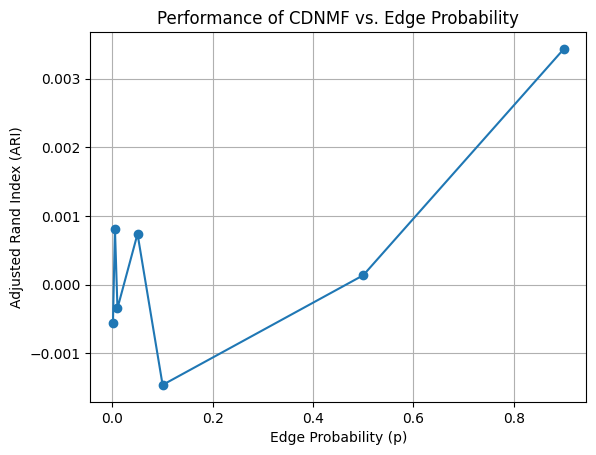

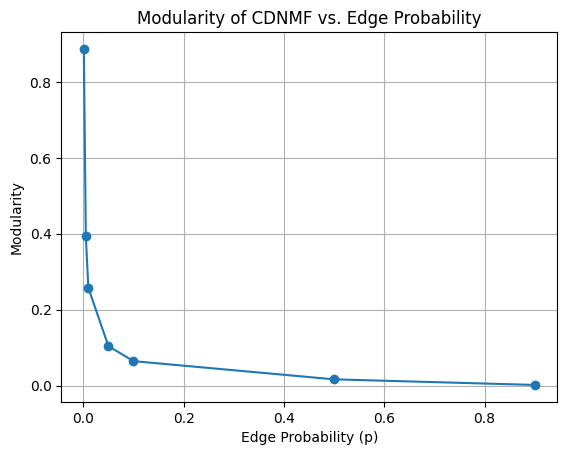

In [237]:
n = 1000  # Number of nodes
num_communities = 10  # Number of ground truth communities
edge_probs = [0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 0.9]  # Edge probabilities to test
aris = []
modularities = []

for p in edge_probs:
    G, features, true_labels = generate_synthetic_network(n, p, num_communities)
    A = graph_to_adjacency_matrix(G)
    
    # Run the CDNMF algorithm
    predicted_labels, P = CDNMF(A, features, k=num_communities, num_iterations=100, beta=0.5) # Best values of num_iterations and beta are 100 and 0.5 respectively

    # Calculate ARI
    ari_score = adjusted_rand_score(true_labels, predicted_labels)
    aris.append(ari_score)

    # Calculate modularity
    modularity = calculate_modularity(A, predicted_labels)
    modularities.append(modularity)
    print(f"Edge probability: {p}, ARI: {ari_score}, Modularity: {modularity}")

# Print and plot ARI scores
import matplotlib.pyplot as plt

plt.plot(edge_probs, aris, marker='o')
plt.xlabel('Edge Probability (p)')
plt.ylabel('Adjusted Rand Index (ARI)')
plt.title('Performance of CDNMF vs. Edge Probability')
plt.grid(True)
plt.show()

# Print and plot modularity scores
plt.plot(edge_probs, modularities, marker='o')
plt.xlabel('Edge Probability (p)')
plt.ylabel('Modularity')
plt.title('Modularity of CDNMF vs. Edge Probability')
plt.grid(True)
plt.show()